[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E5%A4%8F%E5%A4%A9%E9%9B%BB%E8%B2%BB%E7%82%BA%E4%BB%80%E9%BA%BC%E6%9A%B4%E5%A2%9E_%E5%8F%B0%E9%9B%BB%E7%94%A8%E9%9B%BB%E4%BA%94%E5%BC%B5%E5%9C%96.ipynb)

# ⚡ 夏天電費為什麼暴增？用台電真實資料畫出五張圖

> 🎯 **情境**：每年夏天，爸媽看到電費單都會嚇一跳：「冷氣也沒多開啊，怎麼貴這麼多？」台灣電力公司在政府資料開放平台公布了**全台住宅每戶每月平均用電與電費**。今天你要用 Matplotlib 畫出五張圖，用數據回答：**電費暴增，只是因為用得多，還是每一度電也變貴了？**

| 素材檔案 | 內容 |
| --- | --- |
| `台電住宅每戶平均用電與電費.csv` | 台電住宅用戶「每戶」每月平均用電度數與電費（2018 年起，日期是民國年月，例如 10701） |
| `台電各縣市用電統計.csv` | 台電各縣市每月售電量，分成住宅、服務業、工業、農林漁牧（數字有千分位逗號） |

| 📡 資料來源（政府資料開放平台） | 提供機關 | 下載日期 |
| --- | --- | --- |
| [台灣電力公司住宅用戶每月平均用電度數及電費](https://data.gov.tw/dataset/17062) | 台灣電力股份有限公司 | 2026-10-24 |
| [台灣電力公司各縣市住宅、服務業及機關用電統計資料](https://data.gov.tw/dataset/29935) | 台灣電力股份有限公司 | 2026-10-24 |

> ✅ 這些都是**真實的政府開放資料**，依「政府資料開放授權條款－第1版」使用。課堂上統一使用上表日期的快照，所以每個人跑出來的數字都一樣。

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 先把資料讀進來，看看長什麼樣子 |
| ⬜ 任務 2 | 折線圖——每一年的夏天都一樣嗎？ |
| ⬜ 任務 3 | 長條圖——每一度電，價錢一樣嗎？ |
| ⬜ 任務 4 | 散佈圖——用越多，每度越貴？ |
| ⬜ 任務 5 | 直方圖——一般家庭每月電費通常落在哪裡？ |
| ⬜ 任務 6 | 圓餅圖——全台灣的電，誰用掉最多？ |
| ⬜ 任務 7 | 把四張圖拼成一張「電費儀表板」 |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「老闆想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '台電住宅每戶平均用電與電費.csv',
    '台電各縣市用電統計.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['台電住宅每戶平均用電與電費.csv', '台電各縣市用電統計.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：先把資料讀進來，看看長什麼樣子

**白話說明**：用 pandas 的 `read_csv` 讀檔（下一章會詳細教，今天先會用就好）。欄位名稱很長，我們改成短的；日期 `10701` 是**民國 107 年 1 月**，拆成西元年和月份。

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

power = pd.read_csv('台電住宅每戶平均用電與電費.csv')
power.columns = ['年月', '度數', '去年同期度數', '電費', '去年同期電費']   # 欄位改短名
power['年'] = power['年月'] // 100 + 1911          # 10701 // 100 = 107 → 民國 107 + 1911 = 2018
power['月'] = power['年月'] % 100                  # 10701 % 100 = 1
power['每度電價'] = (power['電費'] / power['度數']).round(2)
power.head()

,年月,度數,去年同期度數,電費,去年同期電費,年,月,每度電價
0,10701,247,241,577,546,2018,1,2.34
1,10702,239,239,562,536,2018,2,2.35
2,10703,260,245,618,551,2018,3,2.38
3,10704,255,240,602,539,2018,4,2.36
4,10705,255,257,601,585,2018,5,2.36


## 任務 2：折線圖——每一年的夏天都一樣嗎？

**你想知道**：電費是不是每年夏天都暴增？今年有比較貴嗎？

**白話說明**：把資料排成「月份 × 年份」的表格，每一年畫一條線。舊的年份用淡灰色、最近一年用醒目的顏色——**用顏色告訴讀者要看哪裡**。

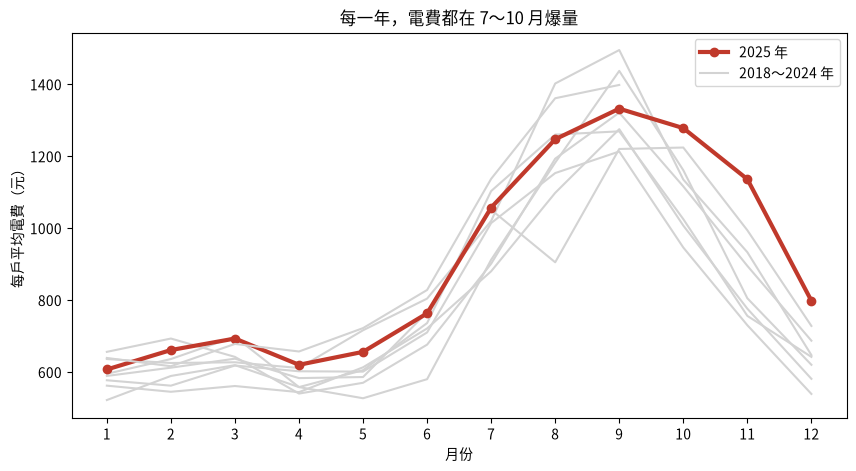

In [4]:
bill = power.pivot_table(index='月', columns='年', values='電費')   # 列：1～12 月；欄：每一年

fig, ax = plt.subplots(figsize=(10, 5))
for year in bill.columns:
    if year == 2025:
        ax.plot(bill.index, bill[year], color='#C0392B', linewidth=3, marker='o', label='2025 年')
    else:
        ax.plot(bill.index, bill[year], color='lightgray', linewidth=1.5)   # 其他年份當背景
ax.plot([], [], color='lightgray', label='2018～2024 年')                 # 只為了讓圖例出現灰色線
ax.set_xticks(range(1, 13))
ax.set_xlabel('月份'); ax.set_ylabel('每戶平均電費（元）')
ax.set_title('每一年，電費都在 7～10 月爆量')
ax.legend()
plt.show()

> 💡 **看懂結果**：每一條線都長得像一座山——**1～5 月約 600 元，7～10 月衝到 1,000～1,400 元**。每一年都一樣，這不是偶然，是季節。

## 任務 3：長條圖——每一度電，價錢一樣嗎？

**你想知道**：夏天電費變貴，只是因為用得比較多嗎？

**白話說明**：「每度電價 = 電費 ÷ 度數」。如果每一度電都一樣價錢，12 根長條應該一樣高。

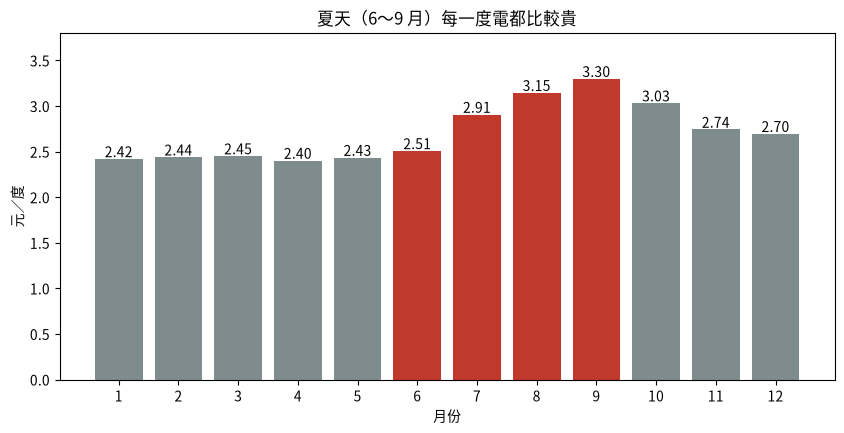

In [5]:
price = power.groupby('月')['每度電價'].mean()                     # 各月份的平均每度電價（groupby 第 9 章會詳細教）
colors = ['#C0392B' if m in (6, 7, 8, 9) else '#7F8C8D' for m in price.index]   # 夏月用紅色

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(price.index, price.values, color=colors)
ax.bar_label(bars, fmt='%.2f')                                      # 長條上方標數字
ax.set_xticks(range(1, 13))
ax.set_ylim(0, 3.8)                                                  # 長條圖的 Y 軸一定要從 0 開始
ax.set_xlabel('月份'); ax.set_ylabel('元／度')
ax.set_title('夏天（6～9 月）每一度電都比較貴')
plt.show()

> 💡 **看懂結果**：非夏月每度約 **2.4 元**，夏月一路漲到 **3.3 元**！這就是台電的「**夏月電價**」：6～9 月用電量大，電價本來就比較高，而且用越多、每度越貴（累進電價）。
> 所以夏天電費暴增是「**用得多 × 每度又比較貴**」的雙重效果。
>
> ⚠️ **為什麼 Y 軸要從 0 開始？** 長條圖靠「長度」比較大小。如果 Y 軸從 2 開始，2.4 和 3.3 看起來會差好幾倍——這是新聞圖表最常見的誤導手法。

## 任務 4：散佈圖——用越多，每度越貴？

**你想知道**：「累進電價」真的看得出來嗎？

**白話說明**：散佈圖看「兩個數字的關係」。X 軸放度數、Y 軸放電費，每一個點是一個月；夏月和非夏月用不同顏色。

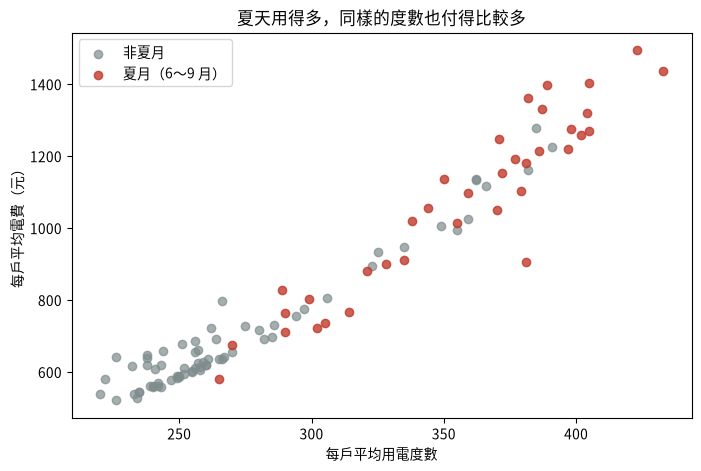

In [6]:
summer = power['月'].isin([6, 7, 8, 9])                             # True / False：是不是夏月

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(power.loc[~summer, '度數'], power.loc[~summer, '電費'], color='#7F8C8D', alpha=0.7, label='非夏月')
ax.scatter(power.loc[summer, '度數'], power.loc[summer, '電費'], color='#C0392B', alpha=0.8, label='夏月（6～9 月）')
ax.set_xlabel('每戶平均用電度數'); ax.set_ylabel('每戶平均電費（元）')
ax.set_title('夏天用得多，同樣的度數也付得比較多')
ax.legend()
plt.show()

> 💡 **看懂結果**：紅點（夏月）幾乎都擠在**右上角**——夏天用得多，電費當然高。再看用電度數差不多的地方（例如 350～400 度）：**紅點大多比灰點高一截**，代表同樣的度數，夏天要付比較多錢。省電最有感的季節，就是夏天。
>
> 🕵️ 右下方有一個特別低的紅點（用了快 400 度，電費卻只有 900 多元），是 2021 年 8 月。真實資料常會有這種「怪點」，遇到時先別急著刪，記下來、去查查那個月發生了什麼事。

## 任務 5：直方圖——一般家庭每月電費通常落在哪裡？

**白話說明**：直方圖把數字切成一格一格的區間，數一數每個區間有幾個月。適合看「大部分落在哪裡、有沒有特別高的」。

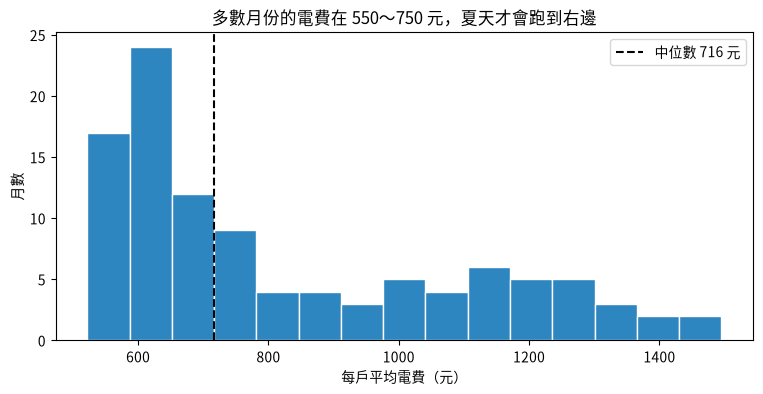

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(power['電費'], bins=15, color='#2E86C1', edgecolor='white')
ax.axvline(power['電費'].median(), color='black', linestyle='--', label=f"中位數 {power['電費'].median():.0f} 元")
ax.set_xlabel('每戶平均電費（元）'); ax.set_ylabel('月數')
ax.set_title('多數月份的電費在 550～750 元，夏天才會跑到右邊')
ax.legend()
plt.show()

## 任務 6：圓餅圖——全台灣的電，誰用掉最多？

**你想知道**：大家都說要節電，那全台灣的電，家裡用掉多少？

**白話說明**：這份縣市用電資料的數字有**千分位逗號**（例如 `"636,471,432"`），加上 `thousands=','` 才會被當成數字。`年月` 是民國年月，`11401～11412` 就是 2025 年。

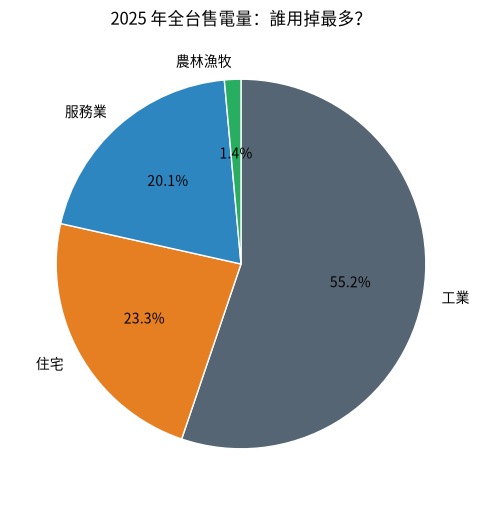

In [8]:
city = pd.read_csv('台電各縣市用電統計.csv', thousands=',')          # thousands=','：把 636,471,432 讀成數字
y2025 = city[(city['年月'] >= 11401) & (city['年月'] <= 11412)]     # 只留 2025 年
share = y2025.groupby('用電性質')['售電量(度)'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(share, labels=share.index, autopct='%1.1f%%', startangle=90, counterclock=False,
       colors=['#566573', '#E67E22', '#2E86C1', '#27AE60'], wedgeprops={'edgecolor': 'white'})
ax.set_title('2025 年全台售電量：誰用掉最多？')
plt.show()

> 💡 **看懂結果**：**工業用電超過一半（55%）**，住宅只占約 23%。家裡節電當然重要，但台灣用電的大頭在工廠——下次看到「全民節電」的新聞，你可以多問一句：工業用電有什麼對策？
>
> ⚠️ 圓餅圖只適合「**加起來是 100%、而且分類很少**（5 類以內）」的資料。分類一多，就改用長條圖。

## 任務 7：把四張圖拼成一張「電費儀表板」

**白話說明**：`plt.subplots(2, 2)` 一次開 4 個小畫布，`axes[0, 0]` 是左上、`axes[1, 1]` 是右下。最後用 `savefig` 存成高解析度圖片，可以直接貼進報告。

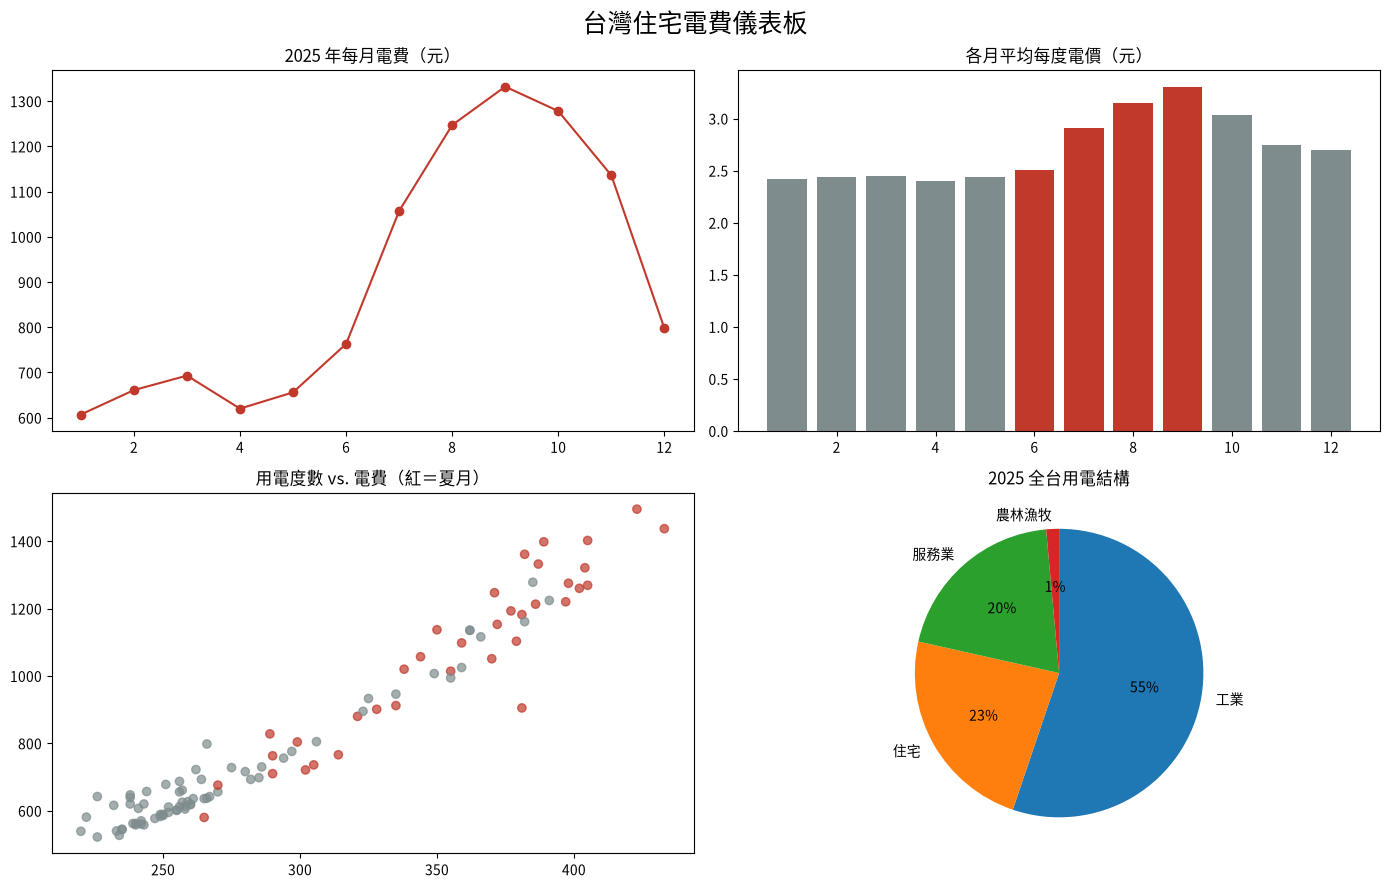

已存成 電費儀表板.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(bill.index, bill[2025], color='#C0392B', marker='o')
axes[0, 0].set_title('2025 年每月電費（元）')
axes[0, 1].bar(price.index, price.values, color=colors)
axes[0, 1].set_title('各月平均每度電價（元）')
axes[1, 0].scatter(power['度數'], power['電費'], c=summer.map({True: '#C0392B', False: '#7F8C8D'}), alpha=0.7)
axes[1, 0].set_title('用電度數 vs. 電費（紅＝夏月）')
axes[1, 1].pie(share, labels=share.index, autopct='%1.0f%%', counterclock=False, startangle=90)
axes[1, 1].set_title('2025 全台用電結構')

fig.suptitle('台灣住宅電費儀表板', fontsize=18)
plt.tight_layout()
plt.savefig('電費儀表板.png', dpi=200, bbox_inches='tight')    # 存成高解析度圖片
plt.show()
print('已存成 電費儀表板.png')

<details><summary>🔄 想看最新資料？點我</summary>

資料每天、每月都在更新。想用今天的數字重跑一次，可以把這段程式貼到新的一格執行：

```python
import urllib.request
urllib.request.urlretrieve('https://service.taipower.com.tw/data/opendata/apply/file/d007004/001.csv', '台電住宅每戶平均用電與電費.csv')
urllib.request.urlretrieve('https://service.taipower.com.tw/data/opendata/apply/file/d007012/001.csv', '台電各縣市用電統計.csv')
# 下載後從任務 1 重新執行；把任務 2 的 2025 改成今年，就能看今年的電費曲線
```

> ⚠️ 開放資料的欄位偶爾會改名或調整，如果最新資料跑出錯誤，正好練習看懂錯誤訊息、對照欄位名稱修正程式。

</details>

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [10]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：2024 年哪個月電費最高？畫出折線圖並標上「全年最高」

<details><summary>💡 卡住了？點我看提示</summary>

`bill[2024]` 取出 2024 年那一欄；`s.idxmax()` 會告訴你「最大值在哪一個索引（月份）」。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
s = bill[___]                                      # 取出 2024 年這一欄
best = s.___()                                     # 電費最高的月份
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s.index, s.values, marker='o', color='#2E86C1')
ax.annotate('全年最高', xy=(best, s[best]), xytext=(best - 2, s[best] + 50),
            arrowprops=dict(arrowstyle='->'))
ax.set_title('2024 年每月電費')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 1
check('best', power[power['年'] == 2024].set_index('月')['電費'].idxmax())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
s = bill[2024]
best = s.idxmax()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s.index, s.values, marker='o', color='#2E86C1')
ax.annotate('全年最高', xy=(best, s[best]), xytext=(best - 2, s[best] + 50),
            arrowprops=dict(arrowstyle='->'))
ax.set_title('2024 年每月電費')
plt.show()
```

</details>

### ✍️ 練習 2：今年比去年貴嗎？把「本期」和「去年同期」電費畫成兩條線

<details><summary>💡 卡住了？點我看提示</summary>

資料本身就有「去年同期電費」欄位。用 `ax.plot` 畫兩次，各給一個 `label`，最後記得 `ax.legend()`。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
last12 = power.tail(12)                            # 最近 12 個月
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(last12['年月'].astype(str), last12['電費'], marker='o', label='本期')
ax.plot(last12['年月'].astype(str), last12[___], marker='o', linestyle='--', label='去年同期')
ax.___()                                           # 顯示圖例
ax.set_title('最近 12 個月：今年 vs. 去年同期電費')
plt.show()

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
last12 = power.tail(12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(last12['年月'].astype(str), last12['電費'], marker='o', label='本期')
ax.plot(last12['年月'].astype(str), last12['去年同期電費'], marker='o', linestyle='--', label='去年同期')
ax.legend()
ax.set_title('最近 12 個月：今年 vs. 去年同期電費')
plt.show()
```

</details>

### ✍️ 練習 3：台北市的用電結構，和全台一樣嗎？畫出台北市 2025 年的圓餅圖

<details><summary>💡 卡住了？點我看提示</summary>

這份資料寫的是「**台**北市」，不是「臺北市」！篩選條件寫錯一個字就會篩不到任何資料。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
taipei = y2025[y2025['縣市'] == ___]
taipei_share = taipei.groupby('用電性質')['售電量(度)'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(taipei_share, labels=taipei_share.index, autopct='%1.1f%%', startangle=90, counterclock=False)
ax.set_title('2025 年台北市用電結構')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('taipei_share', y2025[y2025['縣市'] == '台北市'].groupby('用電性質')['售電量(度)'].sum())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
taipei = y2025[y2025['縣市'] == '台北市']
taipei_share = taipei.groupby('用電性質')['售電量(度)'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(taipei_share, labels=taipei_share.index, autopct='%1.1f%%', startangle=90, counterclock=False)
ax.set_title('2025 年台北市用電結構')
plt.show()
# 台北市幾乎沒有工廠：服務業（商辦、百貨）和住宅才是用電大戶，和全台完全不同
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：先把資料讀進來，看看長什麼樣子
- ✅ 任務 2：折線圖——每一年的夏天都一樣嗎？
- ✅ 任務 3：長條圖——每一度電，價錢一樣嗎？
- ✅ 任務 4：散佈圖——用越多，每度越貴？
- ✅ 任務 5：直方圖——一般家庭每月電費通常落在哪裡？
- ✅ 任務 6：圓餅圖——全台灣的電，誰用掉最多？
- ✅ 任務 7：把四張圖拼成一張「電費儀表板」

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以交給老闆的報告。